# Experiment No. 1 — Real-World Data Collection, Cleaning and Preprocessing using Python

- **Name:** Akshit Negi
- **Course & Branch:** B.TECH CSE
- **CUID:** CU24250214
- **SUBJECT:** Mastery in Data Analytics and Visualizations and Career Advancement
- **SEM & Section:** 5th SEM, "B"

**Aim:** Clean and preprocess a real-world dataset — handle missing values, duplicates, categorical encoding, outliers, scaling, and feature engineering.

**Dataset:** Titanic Survival Dataset, loaded via `seaborn.load_dataset('titanic')` — works directly in Colab, no download needed.

---

## Steps 1–3: Import libraries, load dataset, inspect structure

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

df = sns.load_dataset('titanic')

print(df.head())
print(df.info())
print(df.describe())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-nu

## Step 4: Handle missing values

In [2]:
print("Missing values:\n", df.isnull().sum())

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df.drop(columns=['deck'], inplace=True)   # too many missing values

print("\nMissing values after treatment:\n", df.isnull().sum())

Missing values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing values after treatment:
 survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


## Step 5: Detect and remove duplicates

In [3]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 116
Shape after removing duplicates: (775, 14)


## Step 6: Encode categorical variables

In [4]:
df['sex'] = df['sex'].map({'male': 0, 'female': 1})            # Label Encoding
df = pd.get_dummies(df, columns=['embarked'], drop_first=True)  # One-Hot Encoding

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,False,True
1,1,1,1,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,False,False
2,1,3,1,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,False,True
3,1,1,1,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,False,True
4,0,3,0,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,False,True


## Step 7: Detect and treat outliers (IQR method + box plot)

Fare outlier bounds: [-31.17, 73.42]


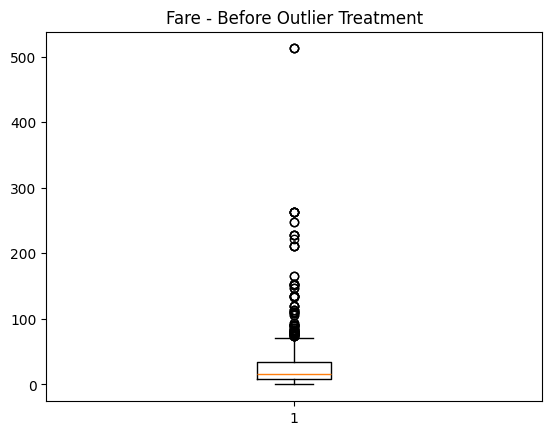

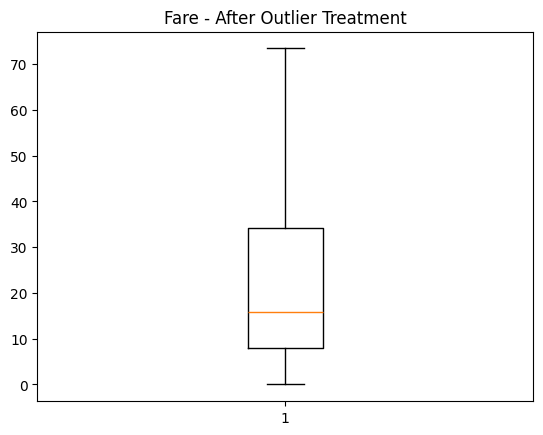

In [5]:
import matplotlib.pyplot as plt

Q1, Q3 = df['fare'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Fare outlier bounds: [{lower:.2f}, {upper:.2f}]")

plt.boxplot(df['fare'])
plt.title("Fare - Before Outlier Treatment")
plt.show()

df['fare'] = df['fare'].clip(lower, upper)   # cap outliers instead of dropping rows

plt.boxplot(df['fare'])
plt.title("Fare - After Outlier Treatment")
plt.show()

## Step 8: Normalize / standardize numerical attributes

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['age', 'fare']] = scaler.fit_transform(df[['age', 'fare']])
df[['age', 'fare']].describe()

,age,fare
count,7.750000e+02,7.750000e+02
mean,2.521281e-16,-3.896525e-17
std,1.000646e+00,1.000646e+00
min,-2.119661e+00,-1.163389e+00
25%,-6.237473e-01,-8.112198e-01
50%,-1.149330e-01,-4.678003e-01
75%,4.665691e-01,3.326910e-01
max,3.664831e+00,2.048557e+00


## Step 9: Feature engineering

In [7]:
df['family_size'] = df['sibsp'] + df['parch'] + 1
df['age_group'] = pd.cut(df['age'], bins=3, labels=['Young', 'Middle', 'Senior'])

df[['family_size', 'age_group']].head()

,family_size,age_group
0,2,Young
1,2,Middle
2,1,Young
3,2,Middle
4,1,Middle


## Step 10: Save the cleaned dataset

In [8]:
df.to_csv('titanic_cleaned.csv', index=False)
print("Cleaned dataset saved as 'titanic_cleaned.csv'")

Cleaned dataset saved as 'titanic_cleaned.csv'


## Questions

**Q1. Why is data preprocessing considered one of the most important phases in data analytics?**

**Ans:** Raw data is often incomplete, inconsistent, or noisy, and analytical or ML models trained on such data produce unreliable results. Preprocessing cleans and structures the data so that patterns extracted from it are accurate and trustworthy — poor preprocessing undermines every step that follows.

**Q2. Explain different methods of handling missing values with suitable examples.**

**Ans:** Common methods include: imputing with mean/median for numerical data (e.g., filling missing `age` with the median age), imputing with mode for categorical data (e.g., filling missing `embarked` with the most frequent port), dropping rows with missing values when they're few, or dropping entire columns when most values are missing (e.g., the `deck` column in Titanic).

**Q3. Differentiate between Label Encoding and One-Hot Encoding.**

**Ans:** Label Encoding assigns each category a single integer (e.g., male=0, female=1), which works well for binary or ordinal categories but can imply a false order for unordered categories. One-Hot Encoding creates a separate binary column for each category, avoiding false ordinal relationships, but increases the number of columns — better suited for nominal categorical variables with more than two values.

**Q4. What are outliers? How can they affect analytical results?**

**Ans:** Outliers are data points that deviate significantly from the rest of the distribution (e.g., an unusually high fare value). They can skew statistical measures like mean and standard deviation, distort correlation and regression results, and cause machine learning models to fit poorly to the majority of the data.

**Q5. Explain the difference between normalization and standardization.**

**Ans:** Normalization rescales values into a fixed range, typically [0, 1], based on the min and max of the data. Standardization rescales values to have a mean of 0 and standard deviation of 1 (z-score), without bounding them to a fixed range — better suited when data roughly follows a normal distribution or contains outliers.

**Q6. Why should duplicate records be removed before analysis?**

**Ans:** Duplicate records artificially inflate the importance of certain data points, bias statistical summaries and model training toward repeated patterns, and can lead to misleading conclusions or overfitting if left unaddressed.

**Q7. What is feature engineering? Give two practical examples.**

**Ans:** Feature engineering is the process of creating new, more informative variables from existing raw data to improve model performance. Examples: combining `sibsp` and `parch` into a single `family_size` feature, and binning a continuous `age` column into categorical `age_group` buckets (Young/Middle/Senior).

**Q8. Which preprocessing techniques would you apply to the IBM HR Employee Attrition dataset and why?**

**Ans:** Missing value treatment for any incomplete records, duplicate removal to avoid biased attrition rates, encoding categorical fields like `Department` and `JobRole` (One-Hot Encoding, since they're nominal), outlier treatment on skewed numeric fields like `MonthlyIncome`, and scaling numerical features like `Age` and `MonthlyIncome` so they contribute proportionally in models sensitive to feature scale (e.g., logistic regression, KNN).

**Q9. How does poor-quality data affect machine learning model performance?**

**Ans:** Poor-quality data (missing values, outliers, inconsistent formats, duplicates) introduces noise and bias that models can learn as false patterns, leading to lower accuracy, poor generalization to new data, and unreliable predictions — commonly summarized as "garbage in, garbage out".

**Q10. Name any three Python libraries commonly used for data preprocessing.**

**Ans:** Pandas (data manipulation and cleaning), NumPy (numerical operations), and Scikit-learn (`sklearn.preprocessing` for scaling and encoding).